# Predicción del precio por noche de alojamientos Airbnb en Ciudad de México

**Maestría en Inteligencia Artificial · Machine Learning (Aprendizaje Supervisado)**
**Autor:** Jaime Astudillo · Proyecto final · noviembre de 2026

*Notebook ejecutable en Google Colab. Los datos se descargan de Inside Airbnb al ejecutarlo; no requiere archivos locales.*

**Resumen.** Con 5 000 anuncios de alojamientos completos de Airbnb en Ciudad de México (*snapshot* del 23 de septiembre de 2026), entreno modelos para estimar el precio por noche a partir de la capacidad, la ubicación, las reseñas, los servicios y la descripción del anuncio, que convierto en variables numéricas con un modelo de lenguaje preentrenado (*transfer learning*). El Random Forest optimizado con Optuna supera a la regresión Ridge en validación cruzada repetida 10×10 (MAE de 647 frente a 721 MXN; la diferencia es significativa con la prueba t corregida, p = 0.006). Evaluado una sola vez en el conjunto de prueba, logra un **MAE de 631 MXN, un RMSE de 1 314 MXN y un R² de 0.54**, frente a un MAE de 984 MXN del baseline que predice la mediana. El número de baños es la variable más influyente, y el modelo subestima los alojamientos más caros.

## 1. Introducción

En Ciudad de México hay más de 30 000 anuncios activos en Airbnb. Para un anfitrión, fijar el precio por noche es una decisión con poca información: si lo fija alto, pierde reservas; si lo fija bajo, pierde ingresos. Para un huésped o un analista urbano, saber si un precio es razonable para lo que ofrece el alojamiento tampoco es evidente. Un modelo que estime el precio de oferta a partir de las características del anuncio (capacidad, ubicación, reseñas, servicios y la propia descripción) sirve como referencia para ambos lados del mercado.

El objetivo de este proyecto es estimar el **precio por noche publicado** de alojamientos completos (departamentos y casas enteras) en Ciudad de México con aprendizaje supervisado, siguiendo un protocolo sin fuga de información: separo un conjunto de prueba antes de ajustar cualquier transformación, optimizo hiperparámetros con validación cruzada repetida solo en entrenamiento, comparo estadísticamente dos técnicas y evalúo el modelo elegido una sola vez en prueba.

Igual que en el ejemplo del curso sobre casas en Quito, el precio publicado no es necesariamente el precio pagado: el resultado es una **estimación del precio de oferta**, no una tasación.

## 2. Datos

Uso el *snapshot* de Ciudad de México del 23 de septiembre de 2026 de **Inside Airbnb** [1], un proyecto que publica datos de anuncios de Airbnb con licencia CC BY 4.0. Cada fila es un anuncio. No uso datos personales de anfitriones (nombres, fotos ni identificadores) como variables.

In [1]:
# Prompt (IA, Claude): «Prepara el entorno del proyecto: instala en Colab lo que falte, importa las
# librerías, fija la semilla y define la fuente de datos de Inside Airbnb para Ciudad de México»
import os, sys, subprocess, warnings
if 'google.colab' in sys.modules:
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'sentence-transformers', 'optuna'], check=True)
os.environ['HF_HUB_DISABLE_PROGRESS_BARS'] = '1'
os.environ['HF_HUB_DISABLE_SYMLINKS_WARNING'] = '1'

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.decomposition import PCA
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.feature_selection import SelectPercentile, f_regression
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.manifold import TSNE
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (RepeatedKFold, cross_val_score, learning_curve, train_test_split,
                                     validation_curve)
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

SEED = 42
DATA_URL = 'https://data.insideairbnb.com/mexico/df/mexico-city/2026-09-23/data/listings.csv.gz'
BLUE, ORANGE, GREEN, GRAY = '#2a78d6', '#eb6834', '#1baf7a', '#898781'
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
print(f'Python {sys.version.split()[0]} | scikit-learn {sklearn.__version__} | pandas {pd.__version__}')

Python 3.13.5 | scikit-learn 1.8.0 | pandas 2.3.2


In [2]:
# Prompt (IA, Claude): «Carga el listado de anuncios desde una copia local si existe o desde la URL
# de Inside Airbnb, y muestra el tamaño y la distribución cruda del precio»
local_copy = os.path.join('data', 'listings.csv.gz')
raw = pd.read_csv(local_copy if os.path.exists(local_copy) else DATA_URL, low_memory=False)
raw['price'] = pd.to_numeric(raw['price'].astype(str).str.replace(r'[$,]', '', regex=True), errors='coerce')

print(f'Anuncios en el snapshot: {len(raw):,} | columnas: {raw.shape[1]}')
print('Tipo de alojamiento:', raw['room_type'].value_counts().to_dict())
empty = [c for c in raw.columns if raw[c].isna().all()]
print(f'Columnas completamente vacías en este snapshot ({len(empty)}):', ', '.join(empty))
print('Precio por noche (MXN), cuantiles:',
      raw['price'].quantile([0, 0.005, 0.05, 0.5, 0.95, 0.995, 1]).round(0).to_dict())

Anuncios en el snapshot: 30,468 | columnas: 90
Tipo de alojamiento: {'Entire home/apt': 20348, 'Private room': 9770, 'Shared room': 275, 'Hotel room': 75}
Columnas completamente vacías en este snapshot (15): neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, bathrooms, calendar_updated, license, instant_bookable
Precio por noche (MXN), cuantiles: {0.0: 137.0, 0.005: 240.0, 0.05: 484.0, 0.5: 1500.0, 0.95: 5446.0, 0.995: 20334.0, 1.0: 1826199.0}


### 2.1 Limpieza

Aplico los filtros en este orden y registro cuántos anuncios quedan después de cada uno:

| Filtro | Justificación |
|---|---|
| Precio publicado y positivo | La variable objetivo debe existir. |
| Solo alojamiento completo (*Entire home/apt*) | Una habitación privada o compartida es otro producto con otro precio; mezclarlos confunde al modelo. |
| Activo: al menos una reseña en los últimos 12 meses | Un anuncio sin actividad reciente puede tener un precio desactualizado. |
| Precio entre 300 y 30 000 MXN por noche | Umbrales fijos de dominio, no calculados con los datos: por debajo de 300 MXN (unos 16 USD) un alojamiento completo es casi seguro un error de captura, y por encima de 30 000 MXN quedan pocos casos extremos. |
| Estancia mínima de hasta 30 noches | Con más de 30 noches el anuncio es en realidad un arriendo mensual. |
| Sin duplicados (misma descripción y mismas coordenadas) | Son unidades clonadas del mismo anfitrión en el mismo edificio; si una queda en entrenamiento y otra en prueba, el modelo «ve» la respuesta. |

Después tomo una **muestra aleatoria de 5 000 anuncios** (semilla 42). No es un filtro de calidad sino una decisión de costo: la rúbrica pide validación cruzada repetida 10×10 y una búsqueda de hiperparámetros con Optuna, y con todos los anuncios un Random Forest tardaría horas. La curva de aprendizaje de la Sección 6 muestra cuánto se pierde por esta decisión.

In [3]:
# Prompt (IA, Claude): «Aplica los filtros de limpieza en orden, reporta los anuncios que quedan tras
# cada uno y toma una muestra aleatoria reproducible de 5 000 anuncios»
filters = [
    ('Con precio publicado', lambda d: d['price'].notna() & (d['price'] > 0)),
    ('Alojamiento completo', lambda d: d['room_type'] == 'Entire home/apt'),
    ('Activo: ≥ 1 reseña en 12 meses', lambda d: d['number_of_reviews_ltm'] >= 1),
    ('Precio entre 300 y 30 000 MXN', lambda d: d['price'].between(300, 30_000)),
    ('Estancia mínima ≤ 30 noches', lambda d: d['minimum_nights'] <= 30),
    ('Sin duplicados (descripción y coordenadas)', lambda d: ~d.duplicated(['description', 'latitude', 'longitude'])),
]
df = raw.copy()
steps = [('Snapshot completo', len(df))]
for label, rule in filters:
    df = df[rule(df)]
    steps.append((label, len(df)))
df = df.sample(n=5_000, random_state=SEED).reset_index(drop=True)
steps.append(('Muestra aleatoria para el costo computacional', len(df)))
pd.DataFrame(steps, columns=['Paso', 'Anuncios'])

,Paso,Anuncios
0,Snapshot completo,30468
1,Con precio publicado,28360
2,Alojamiento completo,18975
3,Activo: ≥ 1 reseña en 12 meses,15972
4,Precio entre 300 y 30 000 MXN,15955
5,Estancia mínima ≤ 30 noches,15948
6,Sin duplicados (descripción y coordenadas),15412
7,Muestra aleatoria para el costo computacional,5000


### 2.2 Variables y diccionario de datos

Construyo las variables con reglas fijas por fila, sin estadísticas del conjunto de datos, así que puedo hacerlo antes de separar entrenamiento y prueba sin fuga de información. Las transformaciones que sí aprenden de los datos (imputación, escalado, codificación, PCA y selección) van dentro del pipeline y se ajustan en cada partición de entrenamiento.

Excluyo a propósito el identificador, la URL, los datos del anfitrión y cualquier variable calculada a partir del precio, como los ingresos estimados que publica Inside Airbnb: usarlas filtraría la respuesta.

In [4]:
# Prompt (IA, Claude): «Construye las variables predictoras a partir de las columnas del anuncio
# (baños, número de servicios, distancia al centro, texto limpio), descarta las columnas vacías y
# muestra un diccionario de datos con tipo, unidad y descripción»
snapshot = pd.Timestamp('2026-09-23')
ZOCALO = (19.4326, -99.1332)  # Plaza de la Constitución, centro histórico

baths = df['bathrooms_text'].str.lower().str.extract(r'([\d.]+)')[0].astype(float)
df['baths'] = baths.where(baths.notna(), np.where(df['bathrooms_text'].str.contains('half', case=False, na=False), 0.5, np.nan))
df['n_amenities'] = df['amenities'].fillna('[]').str.count('",') + df['amenities'].fillna('[]').str.contains('"').astype(int)
df['superhost'] = df['host_is_superhost'].map({'t': 1, 'f': 0})
lat, lon = np.radians(df['latitude']), np.radians(df['longitude'])
dlat, dlon = lat - np.radians(ZOCALO[0]), lon - np.radians(ZOCALO[1])
df['dist_centro_km'] = 2 * 6371 * np.arcsin(np.sqrt(np.sin(dlat / 2) ** 2 + np.cos(lat) * np.cos(np.radians(ZOCALO[0])) * np.sin(dlon / 2) ** 2))
df['description_clean'] = df['description'].fillna('').str.replace(r'<[^>]+>', ' ', regex=True).str.strip()

NUM = ['accommodates', 'bedrooms', 'beds', 'baths', 'latitude', 'longitude', 'dist_centro_km', 'minimum_nights',
       'number_of_reviews', 'review_scores_rating', 'review_scores_location', 'availability_365', 'n_amenities',
       'superhost']
CAT = ['neighbourhood_cleansed', 'property_type']

dictionary = pd.DataFrame([
    ('price', 'objetivo', 'MXN/noche', 'Precio por noche publicado'),
    ('accommodates', 'numérica', 'personas', 'Capacidad máxima de huéspedes'),
    ('bedrooms / beds', 'numérica', 'unidades', 'Dormitorios y camas'),
    ('baths', 'numérica', 'unidades', 'Baños (extraído del texto; medio baño = 0.5)'),
    ('latitude / longitude', 'numérica', 'grados', 'Ubicación aproximada (Airbnb la desplaza hasta ~150 m)'),
    ('dist_centro_km', 'numérica', 'km', 'Distancia en línea recta al Zócalo'),
    ('minimum_nights', 'numérica', 'noches', 'Estancia mínima'),
    ('number_of_reviews', 'numérica', 'reseñas', 'Reseñas totales'),
    ('review_scores_rating / _location', 'numérica', 'escala 0–5', 'Calificación general y de ubicación'),
    ('availability_365', 'numérica', 'días', 'Días disponibles en el próximo año'),
    ('n_amenities', 'numérica', 'unidades', 'Número de servicios declarados'),
    ('superhost', 'binaria', '0/1', 'Anfitrión destacado (superhost)'),
    ('neighbourhood_cleansed', 'categórica', '16 alcaldías', 'Alcaldía de Ciudad de México'),
    ('property_type', 'categórica', 'texto', 'Tipo de propiedad (departamento, condominio, loft, casa…)'),
    ('description', 'texto libre', 'texto', 'Descripción del anuncio (se transforma con transfer learning)'),
], columns=['Variable', 'Tipo', 'Unidad', 'Descripción'])
dictionary

,Variable,Tipo,Unidad,Descripción
0,price,objetivo,MXN/noche,Precio por noche publicado
1,accommodates,numérica,personas,Capacidad máxima de huéspedes
2,bedrooms / beds,numérica,unidades,Dormitorios y camas
3,baths,numérica,unidades,Baños (extraído del texto; medio baño = 0.5)
4,latitude / longitude,numérica,grados,Ubicación aproximada (Airbnb la desplaza hasta...
5,dist_centro_km,numérica,km,Distancia en línea recta al Zócalo
6,minimum_nights,numérica,noches,Estancia mínima
7,number_of_reviews,numérica,reseñas,Reseñas totales
8,review_scores_rating / _location,numérica,escala 0–5,Calificación general y de ubicación
9,availability_365,numérica,días,Días disponibles en el próximo año


## 3. Análisis exploratorio (EDA)

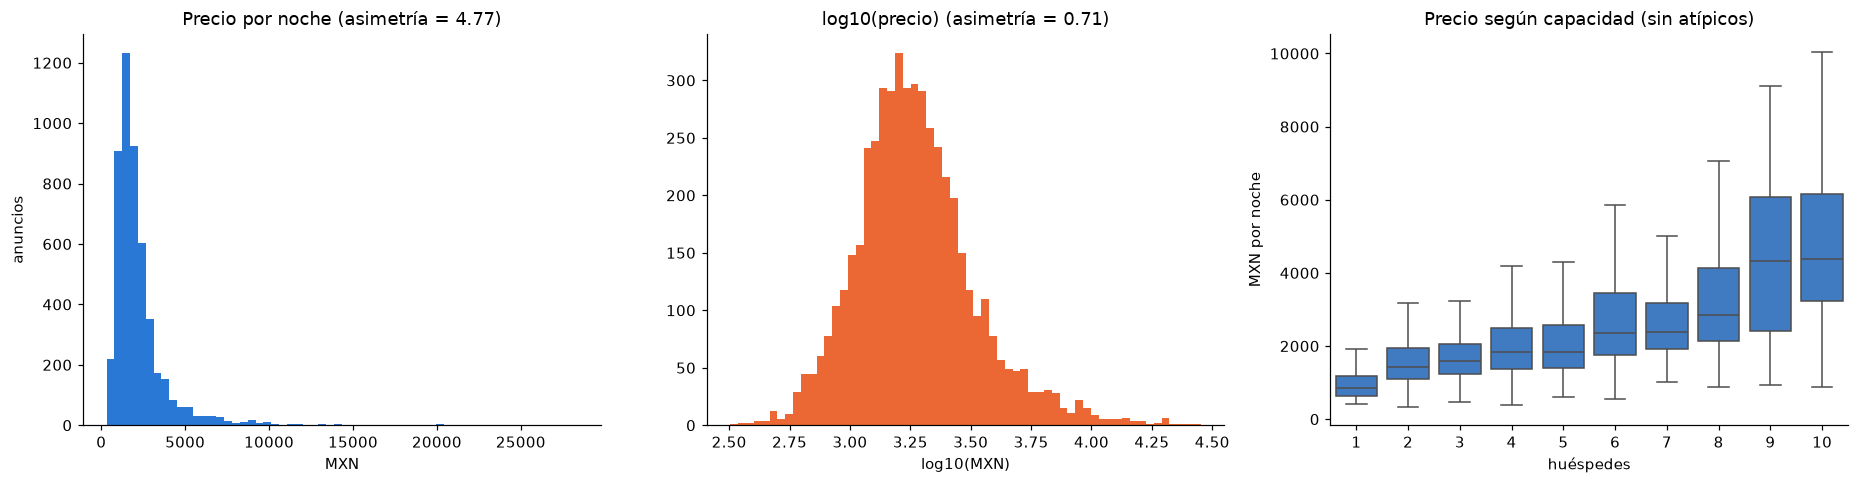

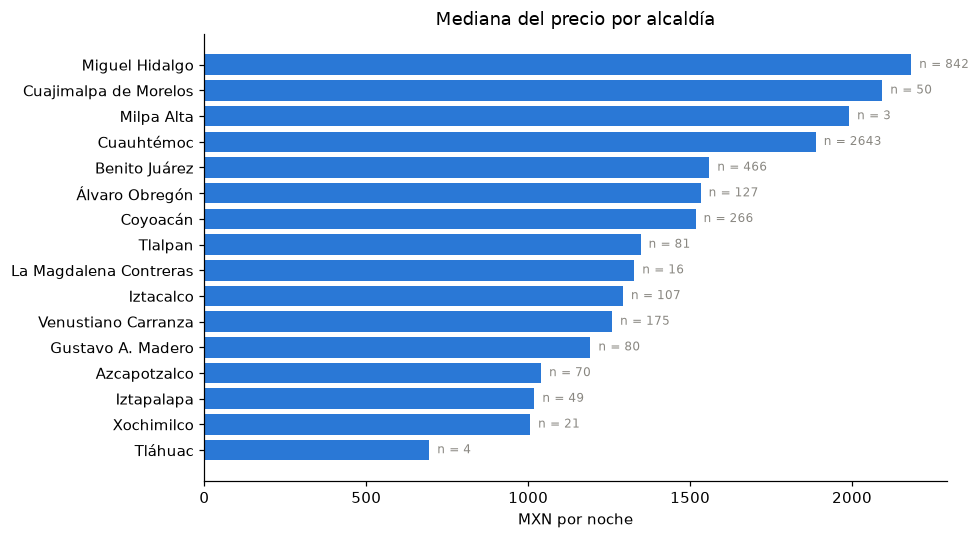

Precio: mediana 1,778 MXN | media 2,266 MXN | p5 814 | p95 5,293


In [5]:
# Prompt (IA, Claude): «Grafica la distribución del precio en escala original y logarítmica con su
# asimetría, y muestra cómo cambia el precio según la capacidad y la alcaldía»
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
axes[0].hist(df['price'], bins=60, color=BLUE)
axes[0].set(title=f"Precio por noche (asimetría = {df['price'].skew():.2f})", xlabel='MXN', ylabel='anuncios')
axes[1].hist(np.log10(df['price']), bins=60, color=ORANGE)
axes[1].set(title=f"log10(precio) (asimetría = {np.log10(df['price']).skew():.2f})", xlabel='log10(MXN)')
sns.boxplot(data=df[df['accommodates'] <= 10], x='accommodates', y='price', color=BLUE, showfliers=False, ax=axes[2])
axes[2].set(title='Precio según capacidad (sin atípicos)', xlabel='huéspedes', ylabel='MXN por noche')
plt.tight_layout()
plt.show()

by_area = df.groupby('neighbourhood_cleansed')['price'].agg(anuncios='size', mediana='median').sort_values('mediana')
fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(by_area.index, by_area['mediana'], color=BLUE)
for i, (n, m) in enumerate(zip(by_area['anuncios'], by_area['mediana'])):
    ax.text(m, i, f'  n = {n}', va='center', fontsize=8, color=GRAY)
ax.set(title='Mediana del precio por alcaldía', xlabel='MXN por noche')
plt.tight_layout()
plt.show()
print(f"Precio: mediana {df['price'].median():,.0f} MXN | media {df['price'].mean():,.0f} MXN | "
      f"p5 {df['price'].quantile(0.05):,.0f} | p95 {df['price'].quantile(0.95):,.0f}")

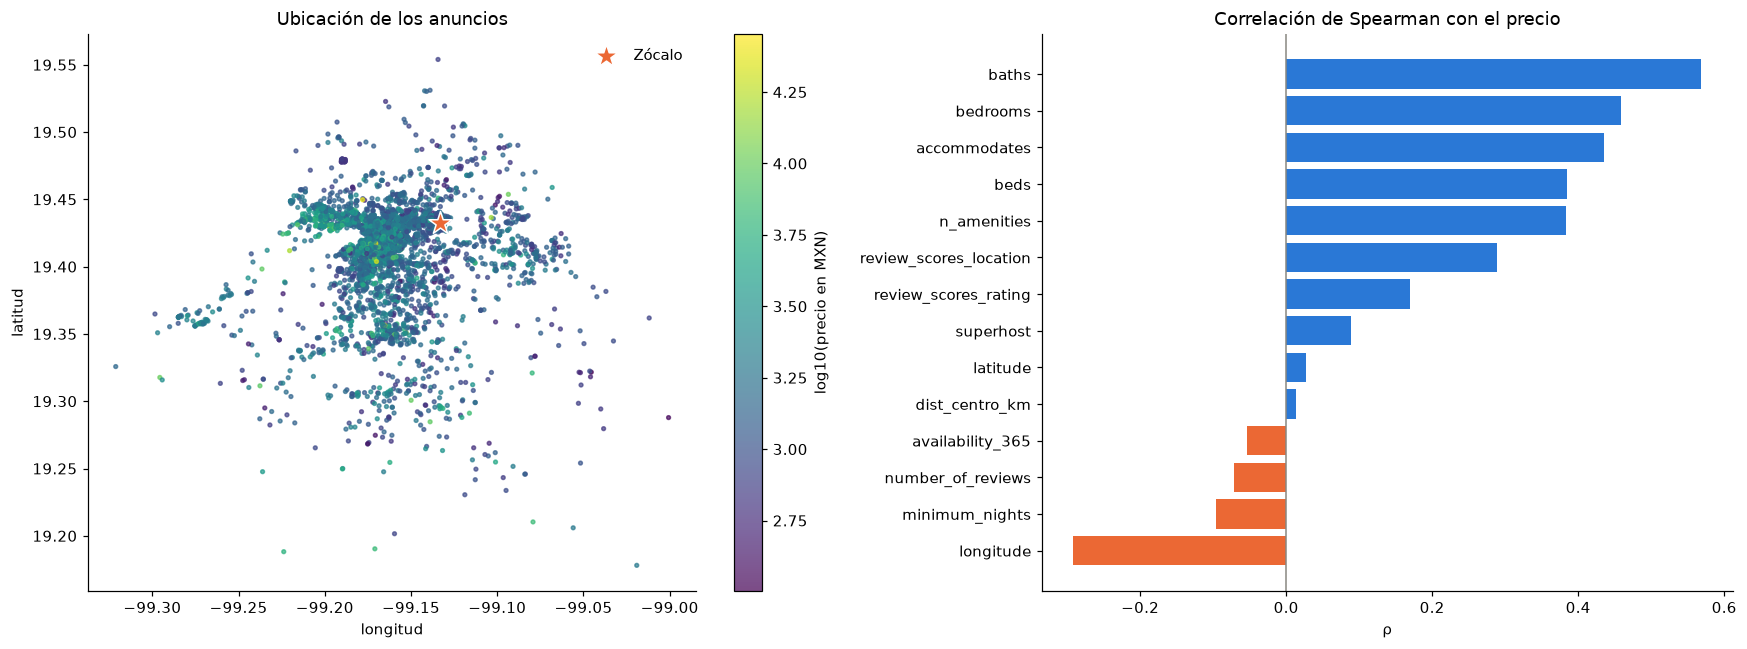

baths                     0.569
bedrooms                  0.459
accommodates              0.436
beds                      0.384
n_amenities               0.383
review_scores_location    0.289
review_scores_rating      0.169
superhost                 0.088
latitude                  0.027
dist_centro_km            0.013
availability_365         -0.054
number_of_reviews        -0.071
minimum_nights           -0.097
longitude                -0.292


In [6]:
# Prompt (IA, Claude): «Dibuja la ubicación de los anuncios coloreada por precio y calcula la
# correlación de Spearman de cada variable numérica con el precio»
fig, axes = plt.subplots(1, 2, figsize=(16, 6), gridspec_kw={'width_ratios': [1.1, 1]})
pts = axes[0].scatter(df['longitude'], df['latitude'], c=np.log10(df['price']), cmap='viridis', s=6, alpha=0.7)
axes[0].scatter(*ZOCALO[::-1], marker='*', s=250, color=ORANGE, edgecolor='white', label='Zócalo')
axes[0].set(title='Ubicación de los anuncios', xlabel='longitud', ylabel='latitud')
axes[0].legend(frameon=False)
fig.colorbar(pts, ax=axes[0], label='log10(precio en MXN)')

spearman = df[NUM].corrwith(df['price'], method='spearman').sort_values()
axes[1].barh(spearman.index, spearman.values, color=[ORANGE if v < 0 else BLUE for v in spearman.values])
axes[1].axvline(0, color=GRAY, lw=1)
axes[1].set(title='Correlación de Spearman con el precio', xlabel='ρ')
plt.tight_layout()
plt.show()
print(spearman.sort_values(ascending=False).round(3).to_string())

In [7]:
# Prompt (IA, Claude): «Resume los valores faltantes y posibles atípicos de las variables predictoras»
missing = df[NUM + CAT].isna().mean().mul(100).round(1)
summary = pd.DataFrame({'faltantes (%)': missing,
                        'mínimo': df[NUM].min().round(2), 'mediana': df[NUM].median().round(2),
                        'máximo': df[NUM].max().round(2)})
print('Descripciones vacías:', int((df['description_clean'] == '').sum()))
summary.sort_values('faltantes (%)', ascending=False)

Descripciones vacías: 23


,faltantes (%),mínimo,mediana,máximo
beds,1.1,1.00,2.00,16.00
accommodates,0.0,1.00,4.00,16.00
baths,0.0,0.00,1.00,16.00
availability_365,0.0,1.00,290.00,365.00
bedrooms,0.0,0.00,2.00,16.00
dist_centro_km,0.0,0.15,4.71,30.73
latitude,0.0,19.18,19.42,19.55
longitude,0.0,-99.32,-99.17,-99.00
minimum_nights,0.0,1.00,1.00,30.00
n_amenities,0.0,2.00,38.00,89.00


**Lo que muestra el EDA**

- **El precio es muy asimétrico.** La mediana es 1 778 MXN por noche y la media 2 266 MXN, con una cola larga de alojamientos caros: la asimetría es 4.77 en escala original y baja a 0.71 en escala logarítmica. Por eso entreno con log(1 + precio).
- **El tamaño y el equipamiento son lo más asociado al precio.** Las mayores correlaciones de Spearman son baños (0.57), dormitorios (0.46), capacidad (0.44), camas (0.38) y número de servicios (0.38). La mediana del precio sube de forma casi monótona con la capacidad.
- **La ubicación importa, pero no como distancia al centro.** La correlación con la distancia al Zócalo es casi nula (0.01), mientras que con la longitud es de −0.29. Las alcaldías más caras son Miguel Hidalgo y Cuajimalpa, al poniente, junto con Cuauhtémoc, que incluye el centro y concentra la mayoría de los anuncios; las más baratas están al oriente y al sur (Iztapalapa, Xochimilco). Como hay zonas caras tanto en el centro como lejos de él, conservo la alcaldía, la latitud y la longitud además de la distancia. La mediana alta de Milpa Alta no es fiable: solo tiene 3 anuncios.
- **Calidad de los datos.** Este *snapshot* trae 15 columnas completamente vacías, entre ellas `host_since` e `instant_bookable`, que había planeado usar, así que las descarto. Entre las variables que uso, solo `beds` tiene faltantes (1.1 %), que se imputan dentro del pipeline, y 23 anuncios no tienen descripción. Los máximos (16 huéspedes, 16 baños, 1 744 reseñas) son raros pero plausibles para casas grandes o anuncios antiguos, así que no los elimino: la escala logarítmica y los árboles reducen su influencia.

## 4. Extracción de características con *transfer learning*

La descripción del anuncio es texto libre (en español, inglés o ambos) y suele mencionar cosas que no están en las columnas: vista, terraza, diseño, cercanía a lugares concretos. Para usarla sin entrenar un modelo de lenguaje, aplico **transfer learning**: el modelo preentrenado `paraphrase-multilingual-MiniLM-L12-v2` de Sentence-Transformers [3], [4] convierte cada descripción en un vector de 384 dimensiones que resume su significado.

Cómo procesa cada descripción:

1. **Tokenización:** divide el texto en subpalabras con el vocabulario multilingüe del modelo.
2. **Codificación:** pasa la secuencia por 12 capas *transformer* («L12» en el nombre); cada token sale con un vector de 384 dimensiones que depende de su contexto.
3. **Pooling:** promedia (*mean pooling*) los vectores de todos los tokens para obtener un solo vector de 384 dimensiones por descripción, y lo normalizo a norma 1.
4. **Longitud máxima:** el modelo lee como máximo 128 tokens; las descripciones más largas se truncan. La celda imprime cuántas.

El modelo está congelado: sus pesos vienen de su entrenamiento original y no aprenden nada de mis datos, así que calcular los vectores antes de la partición no filtra información de prueba. Lo que sí se ajusta a los datos, un PCA que reduce los 384 componentes, va dentro del pipeline.

In [8]:
# Prompt (IA, Claude): «Convierte las descripciones en embeddings con un modelo multilingüe
# preentrenado de sentence-transformers (en GPU si existe) y agrégalos como columnas»
import logging
logging.getLogger('torch.distributed.elastic.multiprocessing.redirects').setLevel(logging.ERROR)
import torch
from sentence_transformers import SentenceTransformer

encoder = SentenceTransformer('paraphrase-multilingual-MiniLM-L12-v2',
                              device='cuda' if torch.cuda.is_available() else 'cpu')
embeddings = encoder.encode(df['description_clean'].tolist(), batch_size=128, show_progress_bar=False,
                            normalize_embeddings=True)
EMB = [f'emb_{i}' for i in range(embeddings.shape[1])]
df = pd.concat([df, pd.DataFrame(embeddings, columns=EMB)], axis=1)
tokens = [len(ids) for ids in encoder.tokenizer(df['description_clean'].tolist(), verbose=False)['input_ids']]
print(f'Embeddings: {embeddings.shape[0]} descripciones x {embeddings.shape[1]} dimensiones')
print(f'Secuencia máxima: {encoder.max_seq_length} tokens | pooling: {encoder[1].pooling_mode} | '
      f'tokens por descripción: mediana {np.median(tokens):.0f} | '
      f'truncadas (> {encoder.max_seq_length} tokens): {np.mean(np.array(tokens) > encoder.max_seq_length):.1%}')

Embeddings: 5000 descripciones x 384 dimensiones
Secuencia máxima: 128 tokens | pooling: mean | tokens por descripción: mediana 100 | truncadas (> 128 tokens): 4.6%


## 5. Partición y pipeline

Separo el **20 % de los anuncios como conjunto de prueba** antes de ajustar cualquier transformación o modelo, con semilla 42 y estratificando por quintiles de precio para que ambos conjuntos tengan una distribución de precios parecida. Como eliminé los duplicados en la limpieza, cada anuncio aparece una sola vez y no hay registros del mismo inmueble repartidos entre entrenamiento y prueba. El conjunto de prueba no se vuelve a usar hasta la Sección 8.

Todo el preprocesamiento va dentro de un `Pipeline` de scikit-learn [2], así que en cada fold se ajusta solo con los datos de entrenamiento de ese fold:

1. **Numéricas:** imputación con la mediana y estandarización.
2. **Categóricas:** imputación con la moda y *one-hot*; las categorías con menos de 30 anuncios se agrupan en una sola.
3. **Texto:** estandarización de los 384 componentes del embedding y PCA a 20 componentes.
4. **Selección de variables tipo filter:** `SelectPercentile` con la prueba F de regresión univariada (`f_regression`) conserva el porcentaje de variables con mayor asociación lineal con el precio; ese porcentaje es un hiperparámetro.
5. **Modelo:** el pipeline completo va dentro de un `TransformedTargetRegressor` que entrena con log(1 + precio), porque el precio es muy asimétrico, pero devuelve las predicciones en MXN. Así, todas las métricas (MAE, RMSE y R²) quedan en pesos mexicanos.

In [9]:
# Prompt (IA, Claude): «Separa entrenamiento y prueba (80/20, estratificado por quintiles de precio)
# y define una función que arme el pipeline completo: preprocesamiento por tipo de columna, PCA del
# texto, selección SelectPercentile con f_regression y el modelo, con el precio en escala log»
X, y = df[NUM + CAT + EMB], df['price']
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=pd.qcut(y, 5, labels=False))
print(f'Entrenamiento: {len(X_train)} anuncios | prueba: {len(X_test)} anuncios')
print(f'Mediana del precio: {y_train.median():,.0f} MXN en entrenamiento | {y_test.median():,.0f} MXN en prueba')


def make_preprocessor(n_text=20):
    return ColumnTransformer([
        ('num', make_pipeline(SimpleImputer(strategy='median'), StandardScaler()), NUM),
        ('cat', make_pipeline(SimpleImputer(strategy='most_frequent'),
                              OneHotEncoder(handle_unknown='infrequent_if_exist', min_frequency=30,
                                            sparse_output=False)), CAT),
        ('txt', make_pipeline(StandardScaler(), PCA(n_components=n_text, random_state=SEED)), EMB),
    ])


def build(model, percentile=100):
    pipe = Pipeline([('pre', make_preprocessor()),
                     ('select', SelectPercentile(f_regression, percentile=percentile)),
                     ('model', model)])
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)


Entrenamiento: 4000 anuncios | prueba: 1000 anuncios
Mediana del precio: 1,782 MXN en entrenamiento | 1,755 MXN en prueba


## 6. Modelos y optimización de hiperparámetros

Comparo dos técnicas de regresión con naturaleza distinta, más un baseline:

- **Baseline:** predice siempre la mediana del precio de entrenamiento. Cualquier modelo útil debe superarlo.
- **Ridge** [7]: regresión lineal con regularización L2. Es simple, interpretable y rápida, pero solo capta relaciones lineales (en log-precio).
- **Random Forest** [6]: promedio de árboles de decisión entrenados con muestras bootstrap y subconjuntos de variables. Capta no linealidades e interacciones, como que una habitación extra valga más en Polanco que en Iztapalapa.

Optimizo los hiperparámetros con **Optuna** [5] (búsqueda bayesiana con el muestreador TPE), maximizando el MAE negativo con **validación cruzada repetida 2×5** (5 folds, 2 repeticiones) solo sobre entrenamiento. Uso 2×5, la opción que la rúbrica permite cuando el costo es alto, porque cada configuración de Random Forest se ajusta 10 veces y Optuna prueba 30 configuraciones por modelo. La comparación estadística de la Sección 7 sí usa 10×10. En ambos modelos el porcentaje de variables que conserva `SelectPercentile` también se optimiza.

In [10]:
# Prompt (IA, Claude): «Optimiza con Optuna (TPE, 30 pruebas por modelo) los hiperparámetros de
# Ridge y de Random Forest, incluido el percentil de SelectPercentile, minimizando el MAE con
# validación cruzada repetida 2x5 sobre entrenamiento»
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)
cv_opt = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)


def cv_mae(model):
    return -cross_val_score(model, X_train, y_train, cv=cv_opt, scoring='neg_mean_absolute_error', n_jobs=-1).mean()


def objective_ridge(trial):
    return cv_mae(build(Ridge(alpha=trial.suggest_float('alpha', 1e-3, 1e5, log=True)),
                        percentile=trial.suggest_int('percentile', 10, 100, step=10)))


def objective_rf(trial):
    rf = RandomForestRegressor(n_estimators=trial.suggest_int('n_estimators', 100, 300, step=50),
                               max_depth=trial.suggest_int('max_depth', 4, 30),
                               min_samples_leaf=trial.suggest_int('min_samples_leaf', 1, 20),
                               max_features=trial.suggest_float('max_features', 0.2, 1.0),
                               random_state=SEED, n_jobs=1)
    return cv_mae(build(rf, percentile=trial.suggest_int('percentile', 10, 100, step=10)))


studies = {}
for name, objective in [('Ridge', objective_ridge), ('Random Forest', objective_rf)]:
    studies[name] = optuna.create_study(direction='minimize', sampler=optuna.samplers.TPESampler(seed=SEED))
    studies[name].optimize(objective, n_trials=30)
    print(f'{name}: mejor MAE CV = {studies[name].best_value:,.1f} MXN | {studies[name].best_params}')

best_ridge = build(Ridge(alpha=studies['Ridge'].best_params['alpha']),
                   percentile=studies['Ridge'].best_params['percentile'])
rf_params = {k: v for k, v in studies['Random Forest'].best_params.items() if k != 'percentile'}
best_rf = build(RandomForestRegressor(**rf_params, random_state=SEED, n_jobs=1),
                percentile=studies['Random Forest'].best_params['percentile'])

Ridge: mejor MAE CV = 719.5 MXN | {'alpha': 758.8552299252854, 'percentile': 80}


Random Forest: mejor MAE CV = 650.8 MXN | {'n_estimators': 250, 'max_depth': 29, 'min_samples_leaf': 2, 'max_features': 0.5795627418679848, 'percentile': 70}


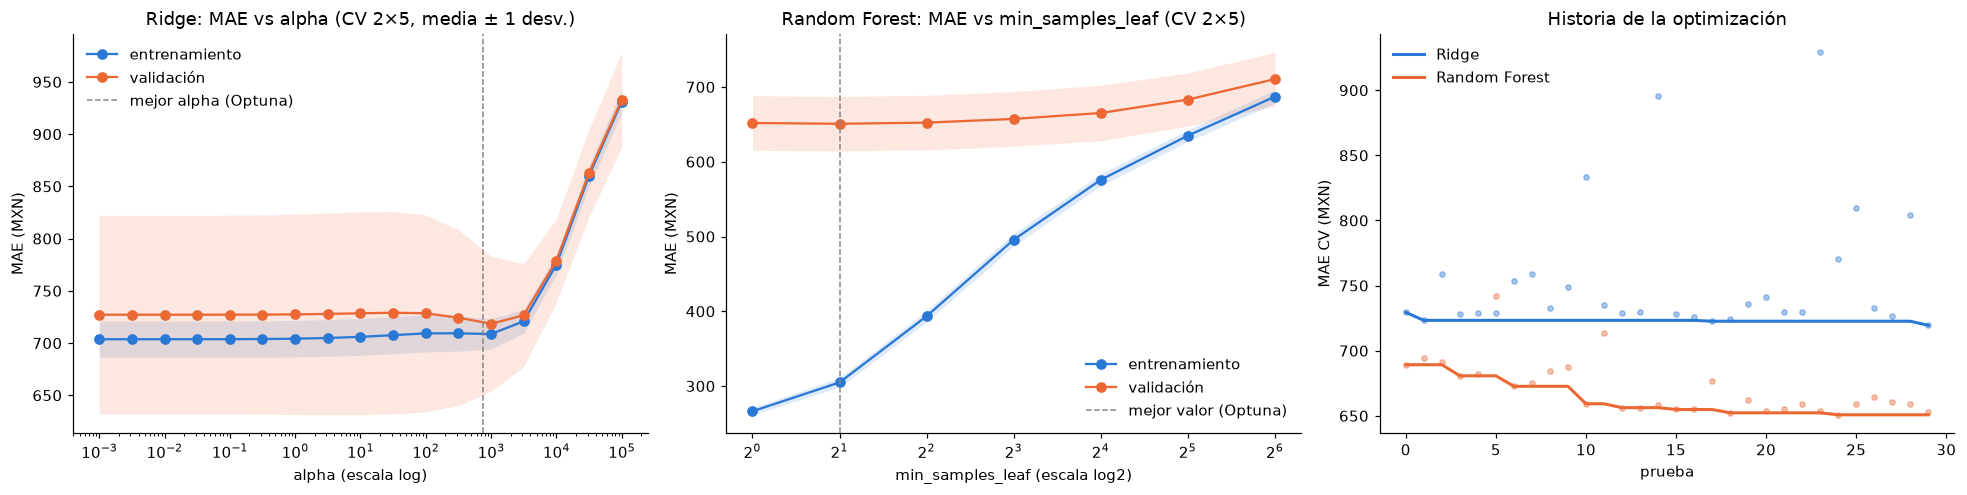

In [11]:
# Prompt (IA, Claude): «Grafica la optimización: curvas de validación (entrenamiento y validación)
# de alpha en Ridge y de min_samples_leaf en Random Forest, con el resto de hiperparámetros en su
# mejor valor, y la historia del mejor MAE de ambos estudios de Optuna»
alphas = np.logspace(-3, 5, 17)
tr, va = validation_curve(build(Ridge(), percentile=studies['Ridge'].best_params['percentile']),
                          X_train, y_train, param_name='regressor__model__alpha', param_range=alphas,
                          cv=cv_opt, scoring='neg_mean_absolute_error', n_jobs=-1)
tr, va = -tr, -va

fig, axes = plt.subplots(1, 3, figsize=(18, 4.6))
for scores_, color, label in [(tr, BLUE, 'entrenamiento'), (va, ORANGE, 'validación')]:
    axes[0].semilogx(alphas, scores_.mean(1), 'o-', color=color, label=label)
    axes[0].fill_between(alphas, scores_.mean(1) - scores_.std(1), scores_.mean(1) + scores_.std(1),
                         color=color, alpha=0.15, lw=0)
axes[0].axvline(studies['Ridge'].best_params['alpha'], color=GRAY, ls='--', lw=1, label='mejor alpha (Optuna)')
axes[0].set(title='Ridge: MAE vs alpha (CV 2×5, media ± 1 desv.)', xlabel='alpha (escala log)', ylabel='MAE (MXN)')
axes[0].legend(frameon=False)

leaves = [1, 2, 4, 8, 16, 32, 64]
tr_rf, va_rf = validation_curve(best_rf, X_train, y_train, param_name='regressor__model__min_samples_leaf',
                                param_range=leaves, cv=cv_opt, scoring='neg_mean_absolute_error', n_jobs=-1)
tr_rf, va_rf = -tr_rf, -va_rf
for scores_, color, label in [(tr_rf, BLUE, 'entrenamiento'), (va_rf, ORANGE, 'validación')]:
    axes[1].semilogx(leaves, scores_.mean(1), 'o-', color=color, label=label, base=2)
    axes[1].fill_between(leaves, scores_.mean(1) - scores_.std(1), scores_.mean(1) + scores_.std(1),
                         color=color, alpha=0.15, lw=0)
axes[1].axvline(studies['Random Forest'].best_params['min_samples_leaf'], color=GRAY, ls='--', lw=1,
                label='mejor valor (Optuna)')
axes[1].set(title='Random Forest: MAE vs min_samples_leaf (CV 2×5)', xlabel='min_samples_leaf (escala log2)',
            ylabel='MAE (MXN)')
axes[1].legend(frameon=False)

for (name, study), color in zip(studies.items(), [BLUE, ORANGE]):
    values = [t.value for t in study.trials]
    axes[2].plot(np.minimum.accumulate(values), color=color, lw=2, label=name)
    axes[2].scatter(range(len(values)), values, color=color, s=12, alpha=0.4)
axes[2].set(title='Historia de la optimización', xlabel='prueba', ylabel='MAE CV (MXN)')
axes[2].legend(frameon=False)
plt.tight_layout()
plt.show()

Ridge: MAE de validación 780 MXN con 320 anuncios -> 720 MXN con 3200 | MAE de entrenamiento final 708 MXN


Random Forest: MAE de validación 720 MXN con 320 anuncios -> 652 MXN con 3200 | MAE de entrenamiento final 305 MXN


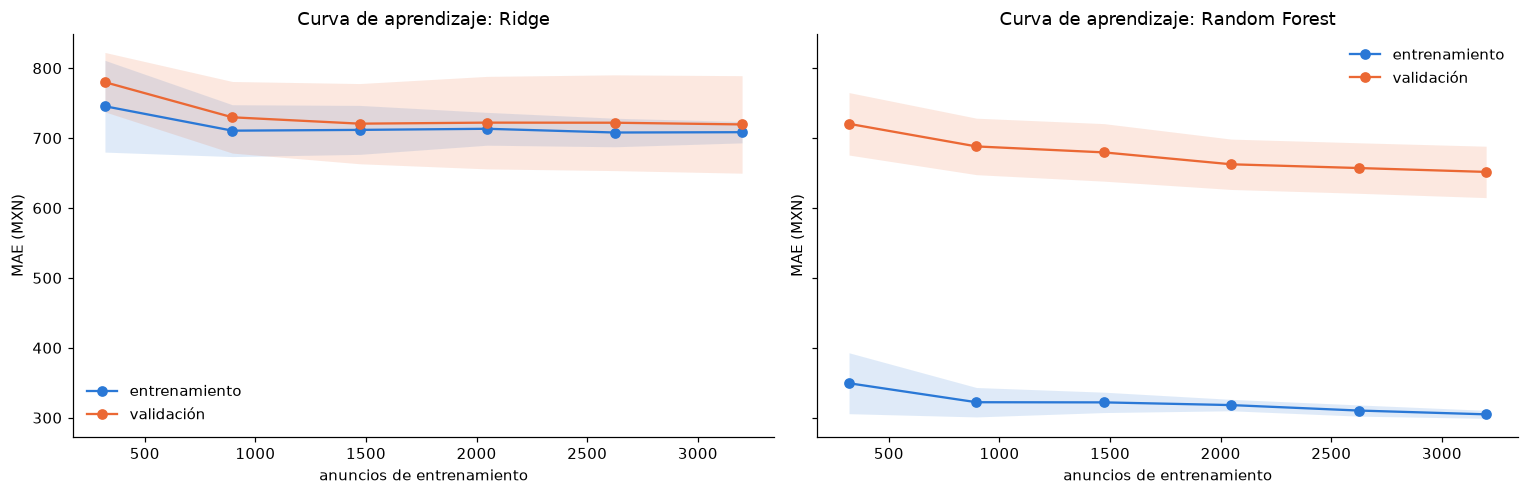

In [12]:
# Prompt (IA, Claude): «Calcula y grafica la curva de aprendizaje de los dos modelos optimizados
# (MAE de entrenamiento y de validación según el tamaño del conjunto de entrenamiento)»
sizes = np.linspace(0.1, 1.0, 6)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6), sharey=True)
for ax, (name, model) in zip(axes, [('Ridge', best_ridge), ('Random Forest', best_rf)]):
    n_used, tr, va = learning_curve(model, X_train, y_train, train_sizes=sizes, cv=cv_opt,
                                    scoring='neg_mean_absolute_error', n_jobs=-1, shuffle=True, random_state=SEED)
    tr, va = -tr, -va
    for scores_, color, label in [(tr, BLUE, 'entrenamiento'), (va, ORANGE, 'validación')]:
        ax.plot(n_used, scores_.mean(1), 'o-', color=color, label=label)
        ax.fill_between(n_used, scores_.mean(1) - scores_.std(1), scores_.mean(1) + scores_.std(1),
                        color=color, alpha=0.15, lw=0)
    ax.set(title=f'Curva de aprendizaje: {name}', xlabel='anuncios de entrenamiento', ylabel='MAE (MXN)')
    ax.legend(frameon=False)
    print(f'{name}: MAE de validación {va.mean(1)[0]:,.0f} MXN con {n_used[0]} anuncios -> '
          f'{va.mean(1)[-1]:,.0f} MXN con {n_used[-1]} | MAE de entrenamiento final {tr.mean(1)[-1]:,.0f} MXN')
plt.tight_layout()
plt.show()

**Resultados de la optimización**

- **Ridge.** El mejor alpha (la λ de la regularización) es 759, conservando el 80 % de las variables, con un MAE de validación de 719.5 MXN. La curva de validación muestra dos regímenes. Con alpha pequeño el MAE apenas cambia, y entrenamiento y validación difieren en unos 20 MXN: el modelo no sobreajusta. Desde alpha ≈ 10⁴ el error sube en las dos curvas a la vez: es subajuste, porque la penalización encoge demasiado los coeficientes.
- **Random Forest.** El mejor modelo usa 250 árboles, profundidad máxima 29, `min_samples_leaf = 2`, `max_features ≈ 0.58` y el 70 % de las variables, con un MAE de validación de 650.8 MXN. En su curva de validación la brecha entre entrenamiento y validación es grande con hojas pequeñas (sobreajuste) y se cierra al aumentar `min_samples_leaf`, pero a costa de subir el error de validación: el mejor compromiso está en hojas pequeñas.
- **Curvas de aprendizaje.** Ridge tiene **sesgo alto**: entrenamiento y validación se juntan pronto (708 y 720 MXN con 3 200 anuncios) y se estabilizan, así que más datos no lo mejorarían; necesitaría un modelo más flexible. Random Forest tiene **varianza alta**: la brecha es grande (305 frente a 652 MXN), pero el error de validación sigue bajando con más datos (de 720 a 652 MXN). Por eso, usar todos los anuncios disponibles en lugar de la muestra de 5 000 probablemente mejoraría al Random Forest; es la principal limitación de mi decisión de muestreo.

## 7. Comparación estadística de Ridge y Random Forest

Comparo **las versiones optimizadas de ambos modelos**, con los mejores hiperparámetros que encontró Optuna en la Sección 6, y no sus valores por defecto: comparar un modelo optimizado con otro sin optimizar no diría cuál técnica es mejor. Uso **validación cruzada repetida 10×10** sobre entrenamiento: los dos modelos se evalúan en exactamente las mismas 100 particiones, así que los MAE quedan **emparejados** por fold.

- **Hipótesis nula (H₀):** el MAE esperado de Ridge y de Random Forest es el mismo.
- **Hipótesis alternativa (H₁):** es distinto (prueba bilateral, α = 0.05).

Los 100 resultados no son observaciones independientes: los conjuntos de entrenamiento de distintos folds comparten la mayor parte de sus anuncios. Una prueba t pareada estándar subestima entonces la varianza y da valores p demasiado pequeños. Por eso uso como prueba principal la **prueba t con varianza corregida** de Nadeau y Bengio [8], recomendada para k-fold repetido por Bouckaert y Frank [9]. Multiplica la varianza de las diferencias por (1/n + n₂/n₁), donde n es el número de resultados (100), n₂ el tamaño de cada fold de validación y n₁ el de entrenamiento. Como contraste reporto también la **prueba de Wilcoxon** de rangos con signo [10], que no supone normalidad pero tampoco corrige la dependencia, y la prueba t pareada sin corregir, para mostrar cuánto cambia la conclusión.

                    MAE medio  desv. estándar  MAE mediano
Baseline (mediana)     1003.0            81.9       1000.8
Ridge                   721.3            93.9        705.5
Random Forest           647.0            55.6        646.0

Diferencia media (Ridge - Random Forest): 74.3 MXN | RF gana en 98 de 100 folds
t corregida (Nadeau-Bengio): t = 2.807, p = 0.0060
Wilcoxon de rangos con signo: W = 6, p = 4.67e-18
t pareada sin corregir (solo como contraste): t = 9.769, p = 3.48e-16


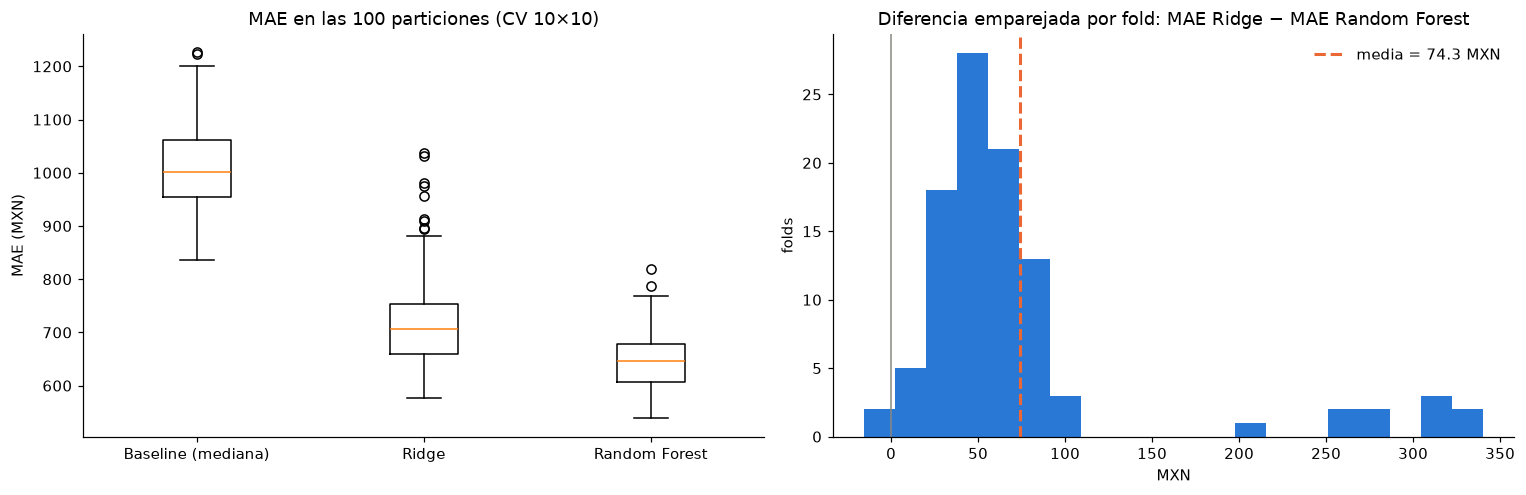

In [13]:
# Prompt (IA, Claude): «Evalúa baseline, Ridge y Random Forest con la misma validación repetida 10x10
# sobre entrenamiento, y compara Ridge y Random Forest con la prueba t corregida de Nadeau-Bengio,
# Wilcoxon y la t pareada sin corregir»
cv_cmp = RepeatedKFold(n_splits=10, n_repeats=10, random_state=SEED)
models = {'Baseline (mediana)': DummyRegressor(strategy='median'), 'Ridge': best_ridge, 'Random Forest': best_rf}
cv_scores = {name: -cross_val_score(model, X_train, y_train, cv=cv_cmp, scoring='neg_mean_absolute_error', n_jobs=-1)
             for name, model in models.items()}

diff = cv_scores['Ridge'] - cv_scores['Random Forest']  # > 0: Random Forest tiene menor MAE
n_res, n_val = len(diff), len(X_train) / 10
n_tr = len(X_train) - n_val
t_corr = diff.mean() / np.sqrt((1 / n_res + n_val / n_tr) * diff.var(ddof=1))
p_corr = 2 * stats.t.sf(abs(t_corr), df=n_res - 1)
wilcoxon = stats.wilcoxon(cv_scores['Ridge'], cv_scores['Random Forest'])
t_naive = stats.ttest_rel(cv_scores['Ridge'], cv_scores['Random Forest'])

print(pd.DataFrame({name: [s.mean(), s.std(), np.median(s)] for name, s in cv_scores.items()},
                   index=['MAE medio', 'desv. estándar', 'MAE mediano']).T.round(1).to_string())
print(f'\nDiferencia media (Ridge - Random Forest): {diff.mean():,.1f} MXN | RF gana en {(diff > 0).sum()} de {n_res} folds')
print(f't corregida (Nadeau-Bengio): t = {t_corr:.3f}, p = {p_corr:.4f}')
print(f'Wilcoxon de rangos con signo: W = {wilcoxon.statistic:.0f}, p = {wilcoxon.pvalue:.2e}')
print(f't pareada sin corregir (solo como contraste): t = {t_naive.statistic:.3f}, p = {t_naive.pvalue:.2e}')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
axes[0].boxplot(list(cv_scores.values()), tick_labels=list(cv_scores.keys()))
axes[0].set(title='MAE en las 100 particiones (CV 10×10)', ylabel='MAE (MXN)')
axes[1].hist(diff, bins=20, color=BLUE)
axes[1].axvline(0, color=GRAY, lw=1)
axes[1].axvline(diff.mean(), color=ORANGE, ls='--', lw=2, label=f'media = {diff.mean():,.1f} MXN')
axes[1].set(title='Diferencia emparejada por fold: MAE Ridge − MAE Random Forest', xlabel='MXN', ylabel='folds')
axes[1].legend(frameon=False)
plt.tight_layout()
plt.show()

**Resultado de la comparación.** Random Forest tiene un MAE medio de 647.0 MXN frente a 721.3 MXN de Ridge (y 1 003.0 MXN del baseline), es mejor en 98 de los 100 folds y su MAE es más estable entre folds (desviación estándar de 55.6 frente a 93.9 MXN). La diferencia media es de 74.3 MXN por noche a favor de Random Forest.

Con la prueba t corregida de Nadeau-Bengio, t = 2.81 y p = 0.006 < 0.05, así que **rechazo H₀**: en este problema Random Forest tiene un error esperado menor que Ridge. Wilcoxon da la misma conclusión con p = 4.7 × 10⁻¹⁸, y la t pareada sin corregir, con p = 3.5 × 10⁻¹⁶. La diferencia de más de diez órdenes de magnitud entre esos valores p y el de la prueba corregida muestra por qué no se pueden tratar los folds como independientes: sin la corrección, las pruebas exageran la evidencia.

**Supuestos y limitaciones.** La prueba t corregida supone que las diferencias por fold son aproximadamente normales; Wilcoxon no lo supone, pero tampoco corrige la dependencia. La conclusión vale para esta muestra de anuncios y estas configuraciones optimizadas. Un valor p pequeño indica que la diferencia difícilmente se explica por la variación entre particiones; no explica por qué Random Forest es mejor ni implica causalidad. La explicación más probable es que el precio depende de interacciones (por ejemplo, el valor de un baño extra cambia según la zona) que un modelo lineal no capta.

## 8. Evaluación final en el conjunto de prueba

Elijo el modelo con menor MAE en la validación cruzada 10×10 (sin mirar el conjunto de prueba), lo reentreno con todo el entrenamiento y lo evalúo **una sola vez** en prueba. Reporto tres métricas en MXN por noche:

- **MAE:** el error absoluto medio; es cuánto se equivoca el modelo en un anuncio típico, en pesos.
- **RMSE:** la raíz del error cuadrático medio; penaliza más los errores grandes, así que es mayor que el MAE cuando hay anuncios muy mal predichos.
- **R²:** la proporción de la variabilidad del precio que explica el modelo (1 es perfecto; 0 es lo mismo que predecir la media).

Como referencia incluyo el baseline de la mediana, ajustado también con entrenamiento.

In [14]:
# Prompt (IA, Claude): «Selecciona el modelo con menor MAE de validación, reentrénalo con todo el
# entrenamiento y evalúalo una sola vez en prueba con MAE, RMSE y R² en MXN, junto al baseline»
chosen = min(['Ridge', 'Random Forest'], key=lambda name: cv_scores[name].mean())
final_model = models[chosen].fit(X_train, y_train)
baseline = DummyRegressor(strategy='median').fit(X_train, y_train)
pred_test = final_model.predict(X_test)


def report(pred):
    return {'MAE (MXN)': mean_absolute_error(y_test, pred),
            'RMSE (MXN)': np.sqrt(mean_squared_error(y_test, pred)), 'R²': r2_score(y_test, pred)}


print(f'Modelo elegido por validación cruzada: {chosen}')
pd.DataFrame({f'{chosen} (final)': report(pred_test), 'Baseline (mediana)': report(baseline.predict(X_test))}).T.round(3)

Modelo elegido por validación cruzada: Random Forest


,MAE (MXN),RMSE (MXN),R²
Random Forest (final),630.790,1313.633,0.539
Baseline (mediana),984.193,1988.075,-0.057


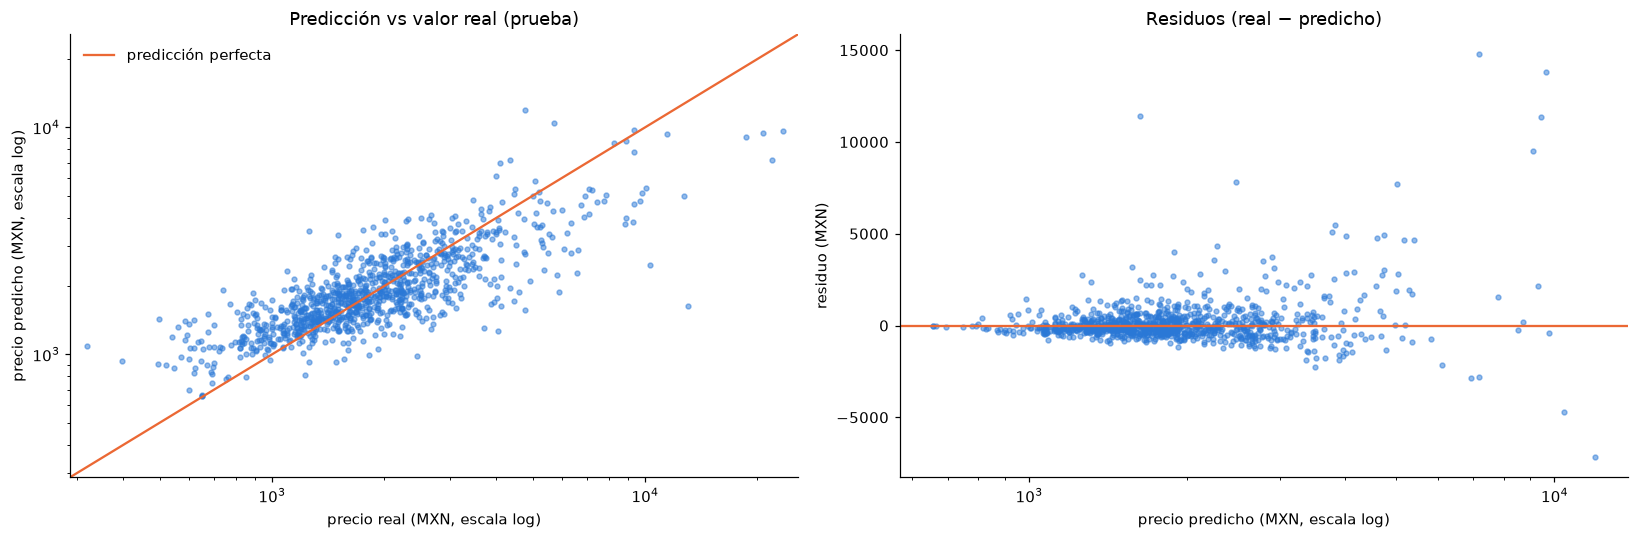

,anuncios,precio_mediano,MAE,error_pct_mediano,sesgo_medio
rango,,,,,
Q1 (más barato),200,953.0,353.1,33.4,350.9
Q2,201,1389.6,293.4,15.5,224.0
Q3,199,1756.0,330.8,12.9,104.4
Q4,200,2296.5,486.9,19.5,-143.9
Q5 (más caro),200,3734.2,1689.9,27.6,-1337.7


In [15]:
# Prompt (IA, Claude): «Grafica predicción vs valor real y los residuos, y resume el error del modelo
# final por quintil de precio real en el conjunto de prueba»
residual = y_test - pred_test
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
axes[0].scatter(y_test, pred_test, s=10, alpha=0.5, color=BLUE)
lims = [y_test.min() * 0.9, y_test.max() * 1.1]
axes[0].plot(lims, lims, color=ORANGE, lw=1.5, label='predicción perfecta')
axes[0].set(xscale='log', yscale='log', xlim=lims, ylim=lims, title='Predicción vs valor real (prueba)',
            xlabel='precio real (MXN, escala log)', ylabel='precio predicho (MXN, escala log)')
axes[0].legend(frameon=False)
axes[1].scatter(pred_test, residual, s=10, alpha=0.5, color=BLUE)
axes[1].axhline(0, color=ORANGE, lw=1.5)
axes[1].set(xscale='log', title='Residuos (real − predicho)', xlabel='precio predicho (MXN, escala log)',
            ylabel='residuo (MXN)')
plt.tight_layout()
plt.show()

by_range = pd.DataFrame({'real': y_test, 'pred': pred_test}).assign(
    rango=pd.qcut(y_test, 5, labels=['Q1 (más barato)', 'Q2', 'Q3', 'Q4', 'Q5 (más caro)']),
    error_abs=lambda d: (d['real'] - d['pred']).abs(),
    error_pct=lambda d: (d['real'] - d['pred']).abs() / d['real'] * 100,
    sesgo=lambda d: d['pred'] - d['real'])
by_range.groupby('rango', observed=True).agg(
    anuncios=('real', 'size'), precio_mediano=('real', 'median'), MAE=('error_abs', 'mean'),
    error_pct_mediano=('error_pct', 'median'), sesgo_medio=('sesgo', 'mean')).round(1)

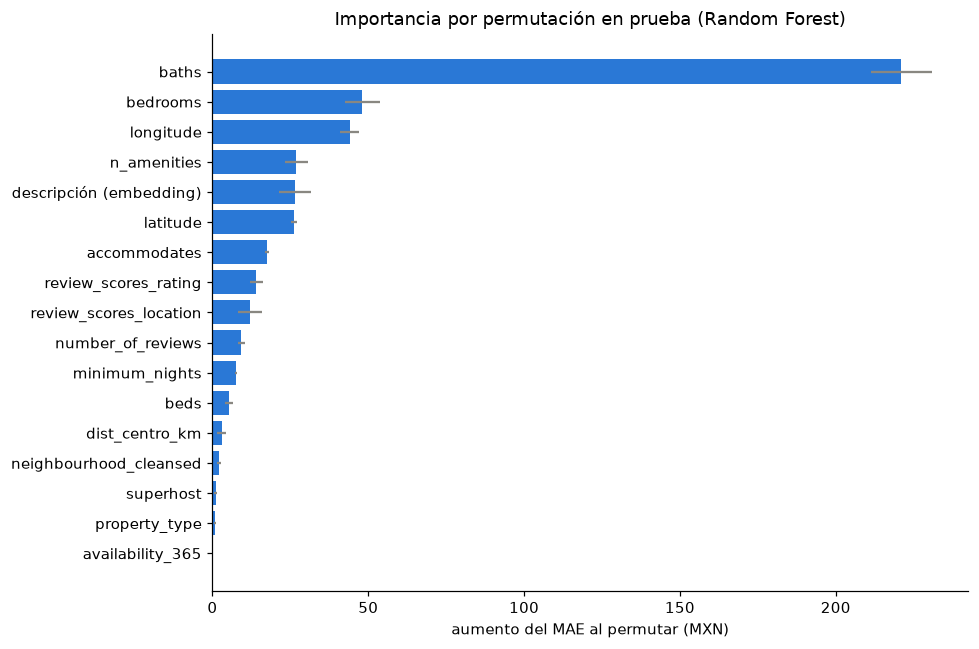

SelectPercentile conservó 38 de 54 variables:
accommodates, bedrooms, beds, baths, latitude, longitude, dist_centro_km, minimum_nights, number_of_reviews, review_scores_rating, review_scores_location, n_amenities, superhost, neighbourhood_cleansed_Azcapotzalco, neighbourhood_cleansed_Benito Juárez, neighbourhood_cleansed_Coyoacán, neighbourhood_cleansed_Cuauhtémoc, neighbourhood_cleansed_Gustavo A. Madero, neighbourhood_cleansed_Iztacalco, neighbourhood_cleansed_Iztapalapa, neighbourhood_cleansed_Miguel Hidalgo, neighbourhood_cleansed_Tlalpan, neighbourhood_cleansed_Venustiano Carranza, neighbourhood_cleansed_Álvaro Obregón, neighbourhood_cleansed_infrequent_sklearn, property_type_Entire guest suite, property_type_Entire home, property_type_Entire loft, property_type_infrequent_sklearn, pca0, pca1, pca2, pca3, pca7, pca10, pca11, pca12, pca18


,aumento del MAE (MXN),desv.
baths,221.0,9.9
bedrooms,48.1,5.6
longitude,44.0,3.1
n_amenities,27.0,3.6
descripción (embedding),26.4,5.0
latitude,26.2,0.9
accommodates,17.5,0.7
review_scores_rating,14.0,2.1


In [16]:
# Prompt (IA, Claude): «Calcula la importancia por permutación en prueba del modelo final, permutando
# juntas las columnas de cada variable original (el embedding completo del texto como un solo grupo),
# y muestra qué variables conservó SelectPercentile»
rng = np.random.default_rng(SEED)
groups = {col: [col] for col in NUM + CAT} | {'descripción (embedding)': EMB}
base_mae = mean_absolute_error(y_test, pred_test)
importance = {}
for name, cols in groups.items():
    increases = []
    for _ in range(5):
        X_perm = X_test.copy()
        X_perm[cols] = X_test[cols].to_numpy()[rng.permutation(len(X_test))]
        increases.append(mean_absolute_error(y_test, final_model.predict(X_perm)) - base_mae)
    importance[name] = (np.mean(increases), np.std(increases))
importance = pd.DataFrame(importance, index=['aumento del MAE (MXN)', 'desv.']).T.sort_values('aumento del MAE (MXN)')

fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(importance.index, importance['aumento del MAE (MXN)'], xerr=importance['desv.'], color=BLUE, ecolor=GRAY)
ax.set(title=f'Importancia por permutación en prueba ({chosen})', xlabel='aumento del MAE al permutar (MXN)')
plt.tight_layout()
plt.show()

pipe = final_model.regressor_
names = pipe.named_steps['pre'].get_feature_names_out()
kept = names[pipe.named_steps['select'].get_support()]
print(f'SelectPercentile conservó {len(kept)} de {len(names)} variables:')
print(', '.join(n.split('__', 1)[1] for n in kept))
importance.sort_values('aumento del MAE (MXN)', ascending=False).round(1).head(8)

## 9. Visualización con t-SNE de lo que ve el modelo

Proyecto a dos dimensiones, con t-SNE [11], las variables que **recibe el modelo final**: la salida del pipeline ajustado justo antes del último paso, es decir, después del preprocesamiento y de la selección de variables. Esa es la representación con la que el modelo trabaja. Uso solo el conjunto de entrenamiento y coloreo cada anuncio por quintil de precio.

t-SNE es una visualización exploratoria: conserva las vecindades locales, pero las distancias entre grupos y su tamaño no tienen un significado directo, y no prueba que existan grupos ni que el precio sea predecible.

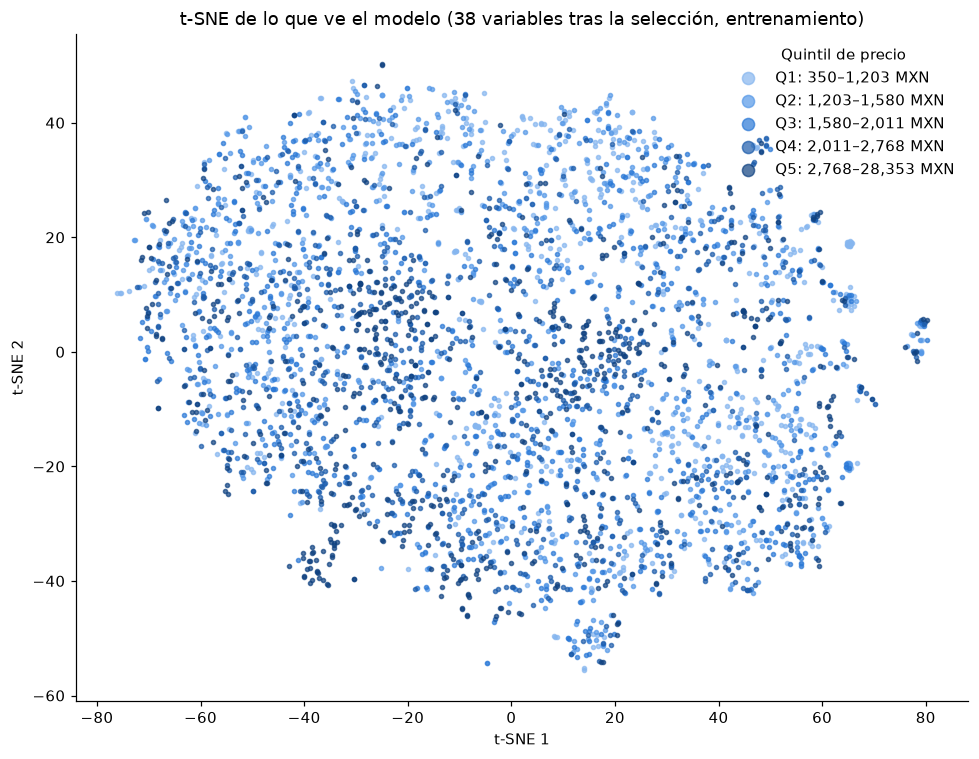

In [17]:
# Prompt (IA, Claude): «Proyecta con t-SNE lo que ve el modelo final: las variables de entrenamiento
# después del preprocesamiento y de la selección (el pipeline ajustado sin su último paso),
# coloreadas por quintil de precio»
seen_by_model = final_model.regressor_[:-1]  # pipeline ya ajustado, sin el modelo: preprocesamiento + selección
Z_train = seen_by_model.transform(X_train)
Z_2d = TSNE(n_components=2, perplexity=30, init='pca', random_state=SEED).fit_transform(Z_train)

quintiles = pd.qcut(y_train, 5)
labels = [f'Q{i + 1}: {iv.left:,.0f}–{iv.right:,.0f} MXN' for i, iv in enumerate(quintiles.cat.categories)]
ramp = ['#86b6ef', '#5598e7', '#2a78d6', '#1c5cab', '#104281']  # secuencial: claro = barato, oscuro = caro
fig, ax = plt.subplots(figsize=(9, 7))
for code_q, (label, color) in enumerate(zip(labels, ramp)):
    mask = (quintiles.cat.codes == code_q).to_numpy()
    ax.scatter(Z_2d[mask, 0], Z_2d[mask, 1], s=7, alpha=0.7, color=color, label=label)
ax.set(title=f't-SNE de lo que ve el modelo ({Z_train.shape[1]} variables tras la selección, entrenamiento)',
       xlabel='t-SNE 1', ylabel='t-SNE 2')
ax.legend(title='Quintil de precio', markerscale=3, frameon=False, loc='best')
plt.tight_layout()
plt.show()

**Lo que muestra el t-SNE.** En el espacio que ve el modelo (38 variables tras la selección) no aparecen grupos separados por precio: los cinco quintiles se mezclan en casi toda la proyección. Sí hay tendencias locales: algunas zonas concentran anuncios caros (tonos oscuros, por ejemplo hacia el centro-izquierda) y otras, baratos (tonos claros, abajo a la derecha), y en los bordes aparecen pequeños grupos compactos, probablemente combinaciones poco frecuentes de las variables categóricas. Es coherente con el R² de 0.54: las variables tienen información sobre el precio, pero anuncios con perfiles parecidos pueden tener precios muy distintos. Como t-SNE solo conserva vecindades locales, no interpreto las distancias entre zonas ni lo uso como prueba de capacidad predictiva.

## 10. Análisis de errores e interpretación

**Desempeño en prueba.** El Random Forest elegido logra en prueba un MAE de 631 MXN, un RMSE de 1 314 MXN y un R² de 0.54: en un anuncio típico se equivoca en unos 630 pesos por noche y explica algo más de la mitad de la variabilidad del precio. Frente al baseline (MAE de 984 MXN y R² de −0.06), reduce el error absoluto medio en un 36 %. El MAE de prueba está en línea con el de validación cruzada (647 MXN), así que la estimación de validación no era optimista. El RMSE duplica al MAE porque unos pocos anuncios tienen errores muy grandes, como se ve en los residuos.

**Errores por rango de precio.** El modelo comprime los precios hacia el centro de la distribución. Sobreestima los anuncios baratos (sesgo medio de +351 MXN en el quintil más barato) y subestima mucho los caros (−1 338 MXN en el más caro, con un MAE de 1 690 MXN). En términos relativos el error es menor en el medio (error mediano de 12.9 % en Q3) y mayor en los extremos (33.4 % en Q1 y 27.6 % en Q5). Los residuos crecen con el precio predicho: los alojamientos de lujo dependen de atributos que las variables no capturan bien, como la vista, el diseño o los servicios premium.

**Importancia de las variables.** Permutar el número de baños aumenta el MAE en 221 MXN, mucho más que cualquier otra variable; le siguen dormitorios (48), longitud (44), número de servicios (27), la descripción del anuncio (26) y latitud (26). La descripción, representada con transfer learning, aporta tanto como la latitud, lo que justifica incluirla. El número de baños probablemente actúa como indicador del tamaño y la categoría del alojamiento. Esta importancia mide cuánto depende el modelo de cada variable para predecir, no un efecto causal: agregar un baño a un departamento no subiría su precio en esa cantidad.

**Selección de variables.** `SelectPercentile` conservó 38 de las 54 variables (el 70 %): 13 de las 14 numéricas (descartó `availability_365`), 12 indicadores de alcaldía, 4 de tipo de propiedad y 9 de los 20 componentes del texto. La selección es univariada: mide por separado la asociación lineal de cada variable con log(precio), así que puede descartar variables que solo aportan en combinación con otras; por eso el porcentaje a conservar fue un hiperparámetro optimizado y no un valor fijo.

## 11. Discusión y limitaciones

- **Precio publicado, no pagado.** Inside Airbnb registra el precio por noche visible en la fecha del *snapshot*; el precio que se paga cambia con la fecha, la duración de la estancia, las tarifas de limpieza y los descuentos. El modelo estima precios de oferta.
- **Una sola fecha.** Los datos son de septiembre de 2026 y los precios de Airbnb son estacionales (temporada alta, eventos), así que el modelo no captura esa variación y puede envejecer rápido.
- **Sesgo de la plataforma y de los filtros.** Solo incluyo alojamientos completos activos con reseñas recientes: el modelo no representa a los anuncios nuevos, a las habitaciones privadas ni a la oferta de alojamiento fuera de Airbnb.
- **Tamaño de muestra.** Usé 5 000 de los 15 412 anuncios elegibles por costo computacional; la curva de aprendizaje indica que el Random Forest mejoraría con más datos.
- **Ubicación aproximada.** Airbnb desplaza las coordenadas publicadas hasta unos 150 m por privacidad, lo que limita la precisión de las variables de ubicación.
- **Texto truncado.** El modelo de lenguaje lee como máximo 128 tokens, así que en las descripciones largas se pierde información (el 4.6 % de las descripciones se truncan).
- **Generalización.** El modelo aprende la geografía de Ciudad de México (alcaldías y coordenadas): no se puede aplicar a otra ciudad sin reentrenarlo con sus datos.

## 12. Conclusiones

1. Con variables del anuncio se puede estimar el precio por noche de un alojamiento completo en Ciudad de México con un error típico de 631 MXN (R² de 0.54 en prueba), un 36 % menos de error que predecir siempre la mediana. Sirve como referencia de precio, pero no para fijar el precio de un alojamiento de lujo, porque los subestima sistemáticamente.
2. Random Forest es significativamente mejor que Ridge en este problema (MAE de 647 frente a 721 MXN en validación 10×10; p = 0.006 con la prueba t corregida), probablemente porque capta interacciones que un modelo lineal no puede representar.
3. Los dos modelos fallan por razones opuestas: Ridge por sesgo (curvas de entrenamiento y validación juntas) y Random Forest por varianza (brecha grande que se reduce con más datos). El siguiente paso con mayor retorno es entrenar el Random Forest con todos los anuncios disponibles.
4. El número de baños es la variable de la que más depende el modelo, seguida del tamaño y la ubicación; la descripción del anuncio, convertida con transfer learning, aporta tanto como la latitud.
5. En este proyecto, las pruebas que no corrigen la dependencia entre folds exageraron la evidencia en más de diez órdenes de magnitud; con validación cruzada repetida hay que usar la versión corregida.

## 13. Uso de inteligencia artificial

El código de este notebook se generó con asistencia de **Claude** (Anthropic) [12], a partir de mi pedido general de un proyecto de aprendizaje supervisado que cubriera todos los ítems de la rúbrica, y de instrucciones por sección. Como pide la guía del curso, cada celda de código empieza con un comentario `# Prompt (IA, Claude): «…»` con la instrucción usada para esa celda. Revisé y ejecuté todo el código, y las decisiones metodológicas (filtros, partición, métricas y pruebas estadísticas) están justificadas en el texto.

## Referencias

[1] Inside Airbnb, «Get the Data: Mexico City, Distrito Federal, Mexico (23 September 2026)», 2026. [En línea]. Disponible: https://insideairbnb.com/get-the-data/. Licencia CC BY 4.0.

[2] F. Pedregosa *et al.*, «Scikit-learn: Machine learning in Python», *J. Mach. Learn. Res.*, vol. 12, pp. 2825–2830, 2011.

[3] N. Reimers e I. Gurevych, «Sentence-BERT: Sentence embeddings using Siamese BERT-networks», en *Proc. EMNLP-IJCNLP*, Hong Kong, 2019, pp. 3982–3992.

[4] N. Reimers e I. Gurevych, «Making monolingual sentence embeddings multilingual using knowledge distillation», en *Proc. EMNLP*, 2020, pp. 4512–4525.

[5] T. Akiba, S. Sano, T. Yanase, T. Ohta y M. Koyama, «Optuna: A next-generation hyperparameter optimization framework», en *Proc. 25th ACM SIGKDD Int. Conf. Knowl. Discov. Data Min.*, 2019, pp. 2623–2631.

[6] L. Breiman, «Random forests», *Mach. Learn.*, vol. 45, n.º 1, pp. 5–32, 2001.

[7] A. E. Hoerl y R. W. Kennard, «Ridge regression: Biased estimation for nonorthogonal problems», *Technometrics*, vol. 12, n.º 1, pp. 55–67, 1970.

[8] C. Nadeau e Y. Bengio, «Inference for the generalization error», *Mach. Learn.*, vol. 52, n.º 3, pp. 239–281, 2003.

[9] R. R. Bouckaert y E. Frank, «Evaluating the replicability of significance tests for comparing learning algorithms», en *Advances in Knowledge Discovery and Data Mining (PAKDD 2004)*, LNCS, vol. 3056, 2004, pp. 3–12.

[10] F. Wilcoxon, «Individual comparisons by ranking methods», *Biometrics Bull.*, vol. 1, n.º 6, pp. 80–83, 1945.

[11] L. van der Maaten y G. Hinton, «Visualizing data using t-SNE», *J. Mach. Learn. Res.*, vol. 9, pp. 2579–2605, 2008.

[12] Anthropic, «Claude», asistente de IA, 2026. [En línea]. Disponible: https://www.anthropic.com/claude.